In [34]:
# import pandas 
import pandas as pd
# import numpy
import numpy as np
# import matplotlib
from matplotlib import pyplot as plt
# make plots appear and be stored within the notebook
%matplotlib inline

In [35]:
#PS2_1
# 读取地震数据文件，使用制标符分隔各列
Sig_Eqs = pd.read_csv('earthquakes-2026-10-14_20-30-32_+0800.tsv', sep='\t')
Sig_Eqs.head()

#1.1
# 按国家分组，降序排列
top20_deaths = Sig_Eqs.groupby(['Country'])['Total Deaths'].sum().sort_values(ascending=False).head(20)

print("死亡人数最多的前 20 个国家")
print(top20_deaths)

死亡人数最多的前 20 个国家
Country
CHINA       2106526.0
TURKEY      1008867.0
IRAN         761656.0
SYRIA        488326.0
ITALY        417297.0
              ...    
PORTUGAL      82572.0
IRAQ          70200.0
CHILE         70175.0
INDIA         63413.0
ISRAEL        58368.0
Name: Total Deaths, Length: 20, dtype: float64


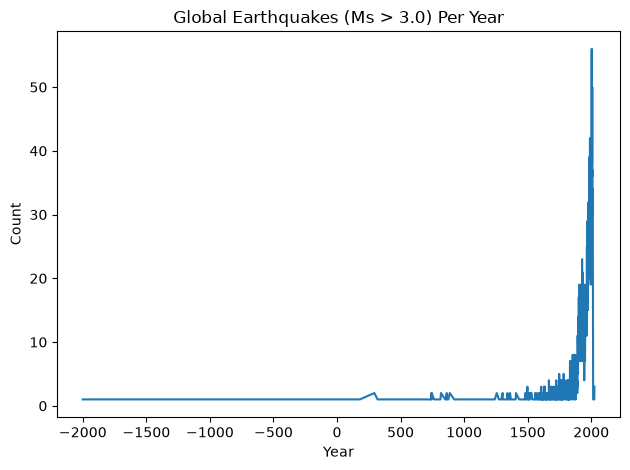

In [36]:
#1.2
#筛选出大于3.0级的地震
eq_ms = Sig_Eqs.loc[Sig_Eqs['Ms'] > 3.0]

#按年分组
year_eq =eq_ms.groupby(['Year'])['Ms'].count()

year_eq.plot(kind='line')
plt.title('Global Earthquakes (Ms > 3.0) Per Year')
plt.xlabel('Year')
plt.ylabel('Count')
# 调整布局
plt.tight_layout()
plt.show()

In [37]:
#1.3
def CountEq_LargestEq(c):

    # 筛选出指定国家的地震记录
    sub = Sig_Eqs[Sig_Eqs['Country'] == c]

    # 地震总次数
    total = len(sub)

    # 删除震级 Mag 为空的数据
    sub2 = sub.dropna(subset=['Mag'])

    # 如果这个国家没有有效的震级数据
    if len(sub2) == 0:
        return total, None, None

    # 从大到小排列
    sub2 = sub2.sort_values('Mag', ascending=False)

    # 选震级最大的一行
    max_row = sub2.iloc[0]

    y = int(max_row['Year'])

    # 获取月份，如果月份缺失，记为未知
    if pd.isna(max_row['Mo']):
        m = "未知"
    else:
        m = int(max_row['Mo'])
        
    # 如果日期缺失，记为未知
    if pd.isna(max_row['Dy']):
        d = "未知"
    else:
        d = int(max_row['Dy'])

    date = str(y) + "-" + str(m) + "-" + str(d)

    # 获取最大地震发生的地点
    loc = max_row['Location Name']

    return total, date, loc

# 遍历所有国家
res = []

for c in Sig_Eqs['Country'].dropna().unique():
    total, date, loc = CountEq_LargestEq(c)
    res.append([c, total, date, loc])

# 将统计结果转换成表格
res_df = pd.DataFrame(
    res,
    columns=['Country', 'Total_Earthquakes', 'Max_Eq_Date', 'Max_Eq_Location']
)

# 按照地震总次数从大到小排列
res_df = res_df.sort_values('Total_Earthquakes', ascending=False)

# 结果太多，只输出前5和后5
pd.set_option('display.max_rows', 10)
res_df

,Country,Total_Earthquakes,Max_Eq_Date,Max_Eq_Location
14,CHINA,626,1668-7-25,CHINA: SHANDONG PROVINCE
33,JAPAN,429,2011-3-11,JAPAN: HONSHU
73,INDONESIA,427,2004-12-26,INDONESIA: SUMATRA: ACEH: OFF WEST COAST
7,IRAN,385,856-12-22,"IRAN: DAMGHAN, QUMIS"
9,TURKEY,359,1939-12-26,TURKEY: ERZINCAN
...,...,...,...,...
154,BURUNDI,1,2004-2-24,BURUNDI: RUYAGA
158,CZECH REPUBLIC,1,2008-11-22,CZECH REPUBLIC: KARVINA
159,MADAGASCAR,1,2017-1-11,MADAGASCAR: ANTSIRABE
160,ZAMBIA,1,2017-2-24,ZAMBIA: KAPUTA


In [38]:
# 通过对比可知， Mag 的有效值最多，所以在震级中选用Mag列的数据
print(Sig_Eqs[['Mag', 'Ms', 'Mw']].describe())

print(Sig_Eqs[['Mag', 'Ms', 'Mw']].isnull().sum())

               Mag           Ms           Mw
count  4910.000000  3102.000000  1937.000000
mean      6.430957     6.567988     6.514249
std       1.033721     0.980499     0.887810
min       1.600000     2.100000     3.600000
25%       5.700000     5.825000     5.800000
50%       6.500000     6.600000     6.500000
75%       7.300000     7.300000     7.200000
max       9.500000     9.100000     9.500000
Mag    1788
Ms     3596
Mw     4761
dtype: int64


C:\Users\小玉\AppData\Local\Temp\ipykernel_33728\1243767628.py:2: DtypeWarning: Columns (0: CALL_SIGN, 1: AA3, 2: AG1, 3: AJ1, 4: AW1, 5: AZ1, 6: CALL_SIGN.1, 7: GA5, 8: GE1, 9: HL1, 10: IA2, 11: KA2, 12: ME1, 13: MW3, 14: OA1, 15: OD1, 16: OD2, 17: SA1, 18: UA1, 19: UG1) have mixed types. Specify dtype option on import or set low_memory=False.
  weather = pd.read_csv("Baoan_Weather_1998_2022.csv")


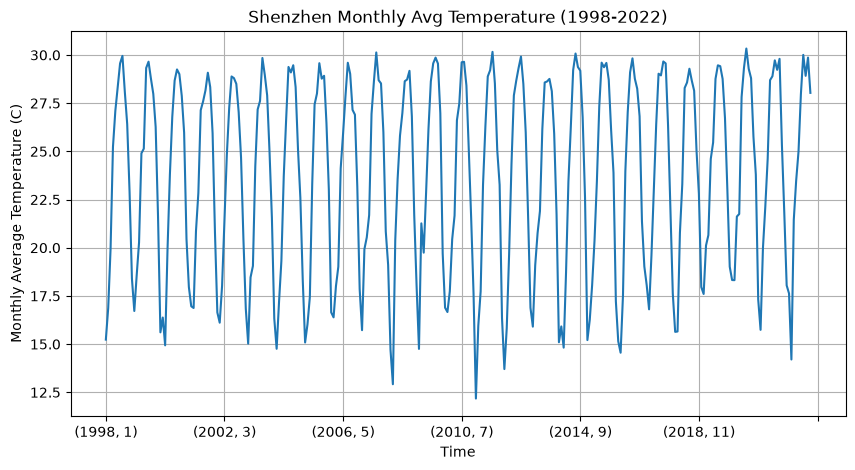

In [39]:
#PS2_2
weather = pd.read_csv("Baoan_Weather_1998_2022.csv")

# user guide要求提取 TMP 列逗号前面的部分
weather['TMP'] = weather['TMP'].str.split(',').str[0]

# 将文字转为数字
weather['TMP'] = weather['TMP'].astype(float)

# 按照 user guide 中指出 +9999 = Missing，可以删掉
weather = weather.loc[weather['TMP'] != 9999]

# user guide 中指出数据里的气温除以10得到正常温度
weather['TMP'] = weather['TMP'] / 10

weather['DATE'] = pd.to_datetime(weather['DATE'])
weather['Year'] = weather['DATE'].dt.year
weather['Month'] = weather['DATE'].dt.month

# 按年份和月份分组求平均
weather.groupby(['Year', 'Month'])['TMP'].mean().plot(figsize=(10, 5))

plt.xlabel('Time')
plt.ylabel('Monthly Average Temperature (C)')
plt.title('Shenzhen Monthly Avg Temperature (1998-2022)')
plt.grid(True)
plt.show()

In [40]:
#PS2_3
# 使用 usecols=range(17) 读取A到Q列
df = pd.read_csv('ibtracs.ALL.list.v04r00.csv', 
                 usecols=range(17), 
                 #跳过第2行单位行
                 skiprows=[1], 
                 #将UCT时间格式转换为daytime时间
                 parse_dates=['ISO_TIME'], 
                 #有的字符串后面可能有空格
                 na_values=['NOT_NAMED', 'NOT_NAMED '])

# 对需要用到的经度、纬度、wind、pres进行数据清洗
col = ['LAT', 'LON', 'WMO_WIND', 'WMO_PRES']
for num in col:
    df[num] = pd.to_numeric(df[num], errors='coerce').replace(-999, np.nan)

#验证数据能够正常读取
df.head()

C:\Users\小玉\AppData\Local\Temp\ipykernel_33728\1008084818.py:3: DtypeWarning: Columns (0: NAME) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('ibtracs.ALL.list.v04r00.csv',


,SID,SEASON,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,WMO_WIND,WMO_PRES,WMO_AGENCY,TRACK_TYPE,DIST2LAND,LANDFALL,IFLAG
0,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 03:00:00,NR,10.9000,80.3000,NaN,NaN,,main,43,0,__________O___
1,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 06:00:00,NR,10.8709,79.8265,NaN,NaN,,main,0,0,__________P___
2,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 09:00:00,NR,10.8431,79.3524,NaN,NaN,,main,0,0,__________P___
3,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 12:00:00,NR,10.8188,78.8772,NaN,NaN,,main,0,0,__________P___
4,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 15:00:00,NR,10.8000,78.4000,NaN,NaN,,main,0,0,__________O___


In [41]:
#3.1
# 按 SID 分组，提取 NAME 以及 WMO_WIND 的最大值
group = df.groupby('SID')[['NAME', 'WMO_WIND']].max()

# WMO_WIND 降序排列 
data = group.sort_values(by='WMO_WIND', ascending=False)

# 取前 10
hurricanes_top10 = data.head(10)

print("最大的10个飓风：")
print(hurricanes_top10)

最大的10个飓风：
                   NAME  WMO_WIND
SID                              
2015293N13266  PATRICIA     185.0
1980214N11330     ALLEN     165.0
2005289N18282     WILMA     160.0
1997253N12255     LINDA     160.0
1988253N12306   GILBERT     160.0
1935241N23291       NaN     160.0
2019236N10314    DORIAN     160.0
2009288N07267      RICK     155.0
1998295N12284     MITCH     155.0
2017242N16333      IRMA     155.0


In [42]:
#3.2
wind_max = df.groupby('SID')['WMO_WIND'].max()

# 对最大风速降序排序
wind_sort = wind_max.sort_values(ascending=False)

# 取前 20
wind_top20 = wind_sort.head(20)

print("风速最大的20个飓风的风速：")
print(wind_top20)

风速最大的20个飓风的风速：
SID
2015293N13266    185.0
1980214N11330    165.0
2005289N18282    160.0
1997253N12255    160.0
1988253N12306    160.0
                 ...  
2007244N12303    150.0
2007225N12331    150.0
2005236N23285    150.0
1994222N11267    150.0
1992230N11325    150.0
Name: WMO_WIND, Length: 20, dtype: float64


In [43]:
#3.3
# 统计 Basin 每个分类的次数
basin_counts = df['BASIN'].value_counts()

print("Basin的数据点数量：")
print(basin_counts)

Basin的数据点数量：
BASIN
WP    236576
SI    160668
SP     67119
EP     62412
NI     55402
SA       119
Name: count, dtype: int64


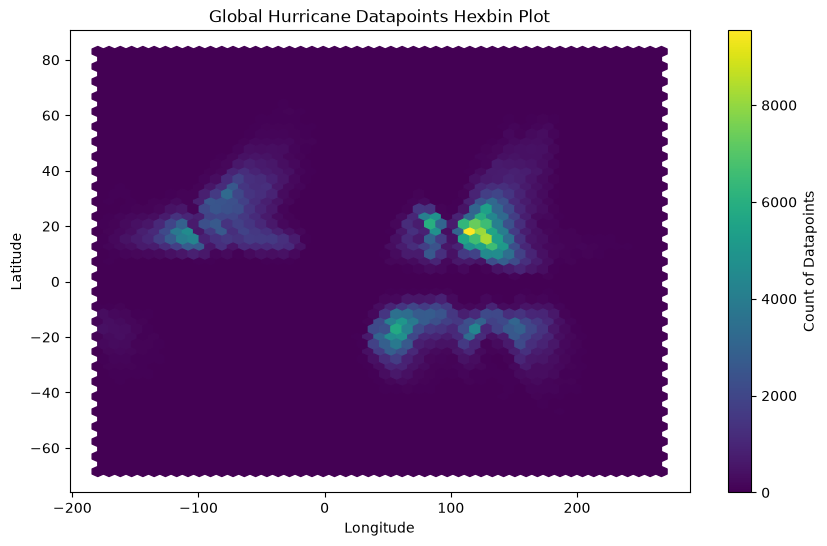

In [44]:
#3.4
plot = df.dropna(subset=['LAT', 'LON'])

# 使用 plt.hexbin 画图
plt.figure(figsize=(10, 6))
plt.hexbin(plot['LON'], plot['LAT'], gridsize=50)

# 增加图例，反映飓风发生的密集程度，颜色越接近黄色，代表该区域飓风数据点越多
plt.colorbar(label='Count of Datapoints')
# 增加标题、横坐标、纵坐标
plt.title('Global Hurricane Datapoints Hexbin Plot')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show() 

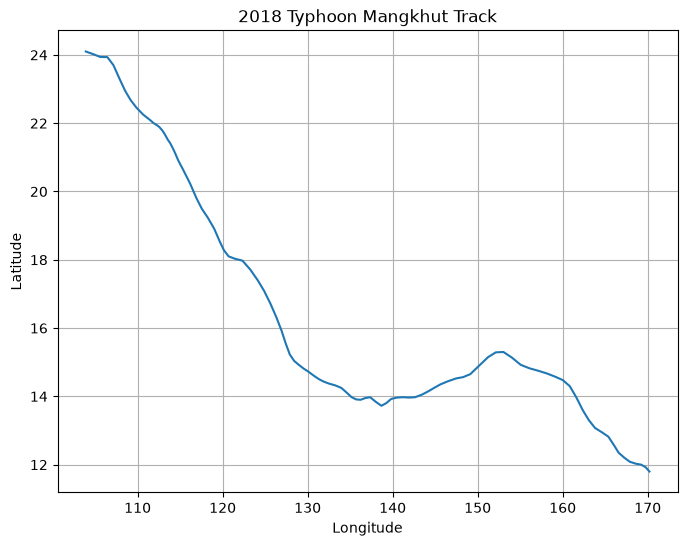

In [55]:
#3.5
# 筛选 NAME 为 MANGKHUT 在2018年的数据
mangkhut = df.loc[(df['NAME'] == 'MANGKHUT') & (df['SEASON'] == 2018)]

# 轨迹图
plt.figure(figsize=(8, 6))
plt.plot(mangkhut['LON'], mangkhut['LAT'])
# 添加标题、经度横坐标、纬度纵坐标
plt.title('2018 Typhoon Mangkhut Track')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True)
plt.show()

In [46]:
#3.6
# 筛选年份>=1970 且 BASIN 是 'WP' 或 'EP' 的数据
wpep = df.loc[(df['SEASON'] >= 1970) & (df['BASIN'].isin(['WP', 'EP']))].copy()

# 将观测时间设置为索引，方便对时间进行分析
wpep.set_index('ISO_TIME', inplace=True)

print("筛选后符合条件的数据共有", len(wpep)," 行。")

筛选后符合条件的数据共有 176352  行。


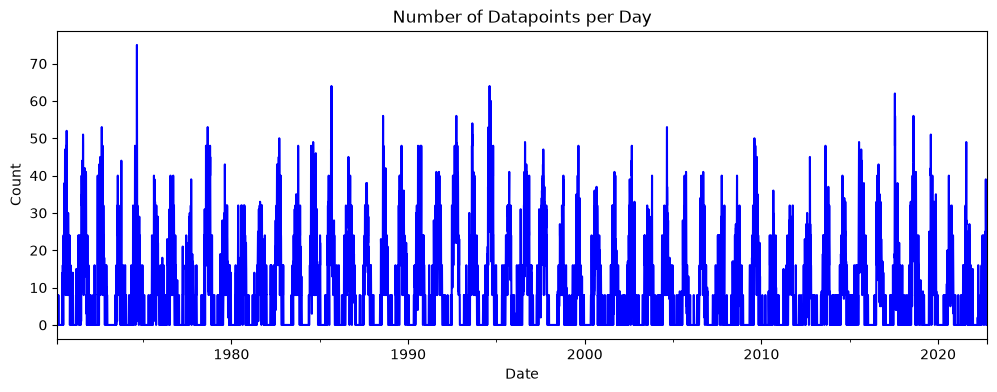

In [47]:
#3.7
# 按日采样，统计每天的数据点数量
daily_counts = wpep.resample('D').size()

plt.figure(figsize=(12, 4))
daily_counts.plot(color='blue')

# 添加标题、date为横坐标，count为纵坐标
plt.title('Number of Datapoints per Day')
plt.xlabel('Date')
plt.ylabel('Count')
plt.show()

In [57]:
#3.8
data8 = daily_counts.reset_index()

# 第一列是时间，第二列是数据量 count
data8.columns = ['ISO_TIME', 'count'] 

# 从时间列中提取一年中的第几天
data8['dayofyear'] = data8['ISO_TIME'].dt.dayofyear

# 计算每一天的多年平均值
climatology = data8.groupby('dayofyear')['count'].mean()

# 输出前几天的结果检验是否正确
print("气候态前5天：")
print(climatology.head())

气候态前5天：
dayofyear
1    1.596154
2    1.384615
3    1.423077
4    1.788462
5    2.019231
Name: count, dtype: float64


In [59]:
#3.9
# 将3.8计算好的 climatology 映射回每日数据中
data8['climatology'] = data8['dayofyear'].map(climatology)

# 距平 = 实际每日数据量 - 气候态平均值
data8['anomaly'] = data8['count'] - data8['climatology']

print("Anomaly：")
print(data8[['ISO_TIME', 'count', 'climatology', 'anomaly']].head())

Anomaly：
    ISO_TIME  count  climatology   anomaly
0 1970-02-19      8     0.981132  7.018868
1 1970-02-20      8     0.905660  7.094340
2 1970-02-21      8     0.811321  7.188679
3 1970-02-22      8     0.622642  7.377358
4 1970-02-23      8     0.509434  7.490566


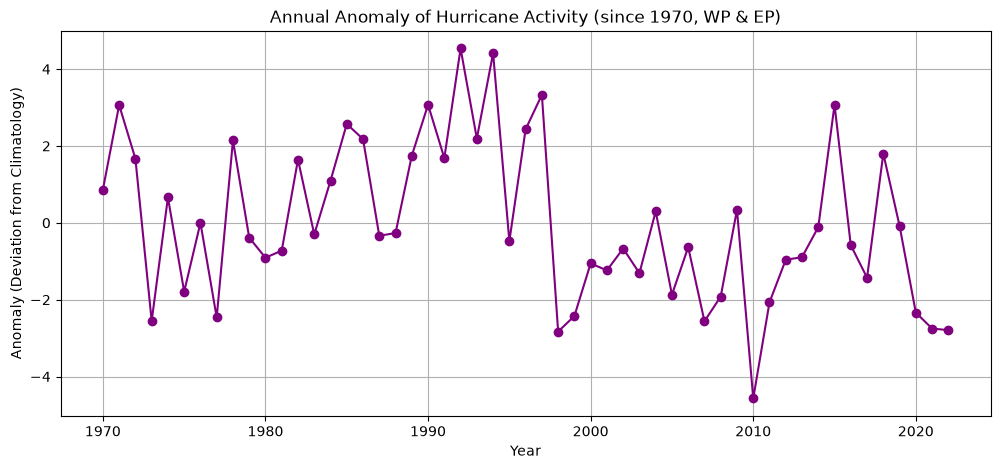

飓风活动异常最突出的年份：
ISO_TIME
1992    4.537501
1994    4.415686
1997    3.330754
Name: anomaly, dtype: float64


In [54]:
#3.10
# 3.10.1
data8 = data8.reset_index()
# 将 ISO_TIME 重新设回索引，可以按年进行重采样
data8.set_index('ISO_TIME', inplace=True)

# 按年重采样，计算每年平均距平值
annual_anomaly = data8['anomaly'].resample('YE').mean()

annual_anomaly.index = annual_anomaly.index.year

# 绘制年度距平折线图
plt.figure(figsize=(12, 5))
annual_anomaly.plot(marker='o', color='purple')
plt.title('Annual Anomaly of Hurricane Activity (since 1970, WP & EP)')
plt.xlabel('Year')
plt.ylabel('Anomaly (Deviation from Climatology)')

# 加网格线，方便对应年份
plt.grid(True) 
plt.show()

# 3.10.2
# 异常突出的年份通过按距平值降序排列判断，取前3
top_anomaly_years = annual_anomaly.sort_values(ascending=False).head(3)

print("飓风活动异常最突出的年份：")
print(top_anomaly_years)

In [51]:
# PS_4
# 4.1 读取并清洗数据
# 使用 comment='#' ，忽略" #注释行 "
data_co2 = pd.read_csv('co2_mm_mlo.csv', comment='#')

print("清洗前的数据：")
print(data_co2.head(3))

# 查看清洗前的数据行数
print("清洗前的数据行数：", len(data_co2))

# 将各列中代表信息缺失的特殊值替换为 NaN
data_co2['ndays'] = data_co2['ndays'].replace(-1, np.nan)
data_co2['sdev'] = data_co2['sdev'].replace(-9.99, np.nan)
data_co2['unc'] = data_co2['unc'].replace(-0.99, np.nan)

# 将时间格式转换为 datetime ，组合 'year' 和 'month'
data_co2['Date'] = pd.to_datetime(data_co2['year'].astype(str) + '-' + 
                                  data_co2['month'].astype(str) + '-01')

# 检查CO2浓度是否有空值
print("average 列缺失值数量：", data_co2['average'].isna().sum())

# 删除 CO2 浓度缺失的月份
data_co2 = data_co2.dropna(subset=['average'])

# 时间从早到晚排列
data_co2 = data_co2.sort_values('Date')

print("清洗后的数据：")
print(data_co2.head(3))
print("清洗后的数据行数：", len(data_co2))

清洗前的数据：
   year  month  decimal date  average  deseasonalized  ndays  sdev   unc
0  1958      3     1958.2027   315.71          314.44     -1 -9.99 -0.99
1  1958      4     1958.2877   317.45          315.16     -1 -9.99 -0.99
2  1958      5     1958.3699   317.51          314.69     -1 -9.99 -0.99
清洗前的数据行数： 823
average 列缺失值数量： 0
清洗后的数据：
   year  month  decimal date  average  deseasonalized  ndays  sdev  unc  \
0  1958      3     1958.2027   315.71          314.44    NaN   NaN  NaN   
1  1958      4     1958.2877   317.45          315.16    NaN   NaN  NaN   
2  1958      5     1958.3699   317.51          314.69    NaN   NaN  NaN   

        Date  
0 1958-03-01  
1 1958-04-01  
2 1958-05-01  
清洗后的数据行数： 823


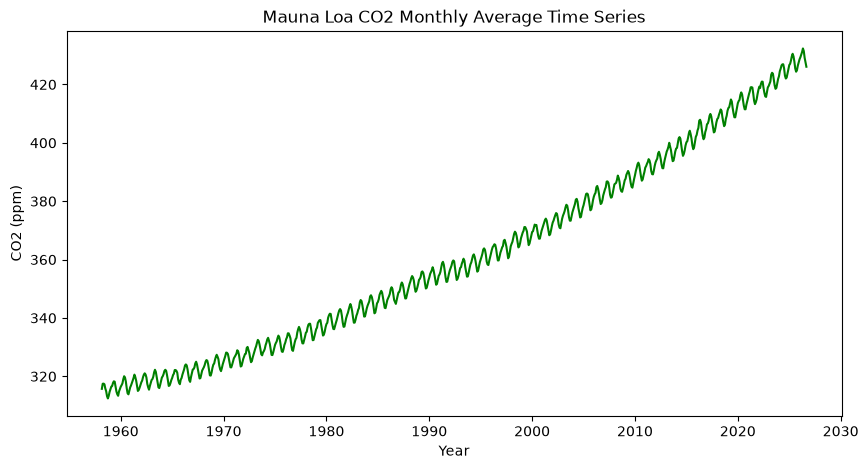

In [52]:
# 4.2
# 绘制 CO2 浓度随时间变化的图表
plt.figure(figsize=(10, 5))

# 添加标题，以 Date 为 x 轴，average 为 y 轴，哦对了，还有单位
plt.plot(data_co2['Date'], data_co2['average'], color='green')
plt.title('Mauna Loa CO2 Monthly Average Time Series')
plt.xlabel('Year')
plt.ylabel('CO2 (ppm)')
plt.show()

In [53]:
# 4.3 要求完成5项数据统计检查

print(" 统计检查报告 ")

# 我选择对 CO2 浓度这一列进行分析
co2 = data_co2['average']

# 1.检查数据总量
print("1. 数据总量:", len(co2))

# 2. 检查缺失值数量
print("2. 缺失值数量:", co2.isna().sum())

# 3. 检查 CO2 最低浓度 ，统一保留两位小数
print("3. CO2 最低浓度:", round(co2.min(), 2), "ppm")

# 4. 检查 CO2 最高浓度
print("4. CO2 最高浓度:", round(co2.max(), 2), "ppm")

# 5. 计算平均值和中位数
print("5. CO2 平均值:", round(co2.mean(), 2), "ppm")
print("   CO2 中位数:", round(co2.median(), 2), "ppm")

# 6. 计算标准差
print("6. 标准差:", round(co2.std(), 2), "ppm")

# 7. 检查整个时期 CO2 浓度的变化
first_co2 = co2.iloc[0]
last_co2 = co2.iloc[-1]
change = last_co2 - first_co2

print("7. 第一个月的 CO2 浓度:", round(first_co2, 2), "ppm")
print("   最后一个月的 CO2 浓度:", round(last_co2, 2), "ppm")
print("   从首月到末月的浓度变化:", round(change, 2), "ppm")

 统计检查报告 
1. 数据总量: 823
2. 缺失值数量: 0
3. CO2 最低浓度: 312.42 ppm
4. CO2 最高浓度: 432.34 ppm
5. CO2 平均值: 361.44 ppm
   CO2 中位数: 356.38 ppm
6. 标准差: 33.51 ppm
7. 第一个月的 CO2 浓度: 315.71 ppm
   最后一个月的 CO2 浓度: 426.07 ppm
   从首月到末月的浓度变化: 110.36 ppm
